# AI4I Predictive Maintenance - First Working Vertical Slice

## Overview
This notebook creates the first working vertical slice for the AI4I predictive maintenance dataset CIS 480 Capstone project.

The objectives are to:

- Load the dataset
- Clean and transform data
- Identify predictors
- Check failure distribution
- Produce verified summary
- Create logistic regression baseline

## 1. Imports and Display Settings

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Load the Raw Data

In [2]:
file_path = "../../data/raw/ai4i2020.csv"

df_raw = pd.read_csv(file_path)

df_raw.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 3. Findings from Initial Data Analysis

Initial data analysis from raw_data_analysis.ipynb found that the data is very clean with no missing fields, and no duplicates.

In [3]:
print("Duplicate rows:", df_raw.duplicated().sum())

Duplicate rows: 0


In [4]:
missing = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percent": df_raw.isna().mean() * 100
})

missing

,Missing_Count,Missing_Percent
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


Inital analysis did find inconsisencies with the machine failure and failure labels.

In [5]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

any_failure = df_raw[failure_cols].max(axis=1)

pd.crosstab(
    df_raw["Machine failure"],
    any_failure,
    rownames=["Machine failure"],
    colnames=["Any failure flag"]
)

Any failure flag,0,1
Machine failure,,
0,9643,18
1,9,330


## 3. Copy Raw Data and Apply Cleaning from Initial Analysis

As shown in step 2, there are 27 records with inconsistencies between overall Machine failure label and the individual failure-mode indicators. 

Because the AI4I dataset defines machine failure based on the occurrence of the documented failure modes, these inconsistent records will be removed prior to modeling.

This reduced the dataset from 10,000 to 9,973 observations.

In [6]:
df = df_raw

In [7]:
any_failure = df[failure_cols].max(axis=1)

inconsistent = df["Machine failure"] != any_failure

print("Rows before:", len(df))
print("Inconsistent rows:", inconsistent.sum())

df = df.loc[~inconsistent].copy()

print("Rows after:", len(df))

Rows before: 10000
Inconsistent rows: 27
Rows after: 9973


## 4. Identify Predictors

UDI and Product ID are unique identifiers and will not be used as predictors.

The five indpendent failure modes TWF, HDF, PWF, OSF, and RNF determine if the 'machine failure' label is set to 1. Therefore these will not be used as predictors as it is not transparent which one of these failure modes cause the process to fail.

In [8]:
predictors = [
    'Type', 
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]
outcome = 'Machine failure'

## 5. Check Failure Distribution


Failure Distribution:
 - No Failure (0): 9643 (96.69%)
 - Failure (1): 330 (3.31%)


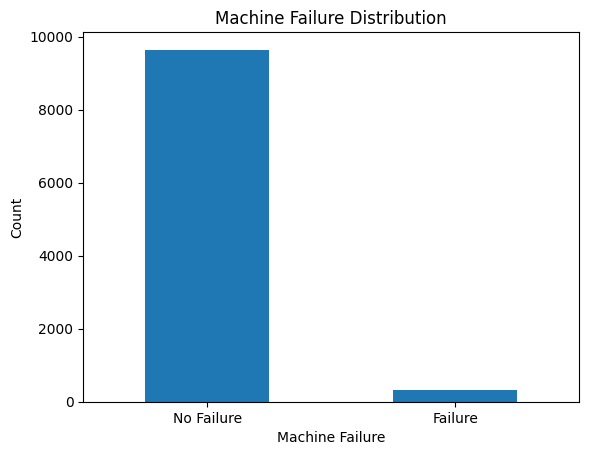

In [9]:
failure_counts = df[outcome].value_counts()
failure_percentages = df[outcome].value_counts(normalize=True) * 100

print("\nFailure Distribution:")
print(f" - No Failure (0): {failure_counts.get(0, 0)} ({failure_percentages.get(0, 0):.2f}%)")
print(f" - Failure (1): {failure_counts.get(1, 0)} ({failure_percentages.get(1, 0):.2f}%)")

df["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.xticks([0, 1], ["No Failure", "Failure"], rotation=0)
plt.show()

## 6. Verify Data

In [10]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

assert(df.shape[0] == 9973)
assert(df.shape[1] == 14)

Rows: 9973
Columns: 14


In [11]:
print("Total missing values:", df.isna().sum().sum())

assert df.isna().sum().sum() == 0

Total missing values: 0


In [12]:
print("Duplicate rows:", df.duplicated().sum())

assert df.duplicated().sum() == 0

Duplicate rows: 0


In [13]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

any_failure = df[failure_cols].max(axis=1)

failure_mismatches = (
    df["Machine failure"] != any_failure
).sum()

print("Failure label mismatches:", failure_mismatches)

assert failure_mismatches == 0

Failure label mismatches: 0


In [14]:
binary_cols = [
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

for col in binary_cols:
    print(col, sorted(df[col].unique()))

for col in binary_cols:
    assert df[col].isin([0, 1]).all()

Machine failure [0, 1]
TWF [0, 1]
HDF [0, 1]
PWF [0, 1]
OSF [0, 1]
RNF [0, 1]


In [15]:
print(df["Type"].value_counts())

assert set(df["Type"].unique()) <= {"L", "M", "H"}

Type
L    5984
M    2991
H     998
Name: count, dtype: int64


In [16]:
print("Unique UDI:", df["UDI"].nunique())
print("Unique Product IDs:", df["Product ID"].nunique())

assert df["UDI"].is_unique
assert df["Product ID"].is_unique

Unique UDI: 9973
Unique Product IDs: 9973


In [17]:
assert (df["Rotational speed [rpm]"] > 0).all()
assert (df["Torque [Nm]"] >= 0).all()
assert (df["Tool wear [min]"] >= 0).all()
assert (df["Air temperature [K]"] > 0).all()
assert (df["Process temperature [K]"] > 0).all()

In [18]:
predictors = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

outcome = "Machine failure"

assert outcome not in predictors

leakage_cols = {"TWF", "HDF", "PWF", "OSF", "RNF"}

assert leakage_cols.isdisjoint(predictors)

## 7. Verified Summary

In [19]:

display(Markdown("## AI4I 2020 Predictive Maintenance Dataset Summary"))

overview = pd.DataFrame({
    "Metric": [
        "Total Observations",
        "Number of Predictors",
        "Outcome Variable"
    ],
    "Value": [
        f"{len(df):,}",
        len(predictors),
        outcome
    ]
})

display(overview)

predictor_table = pd.DataFrame({
    "Predictor": predictors
})

display(Markdown("### Permitted Predictors"))
display(predictor_table)


failure_summary = pd.DataFrame({
    "Outcome": ["Normal Operation", "Machine Failure"],
    "Value": [0, 1],
    "Count": [
        failure_counts.get(0, 0),
        failure_counts.get(1, 0)
    ],
    "Percent": [
        failure_percentages.get(0, 0),
        failure_percentages.get(1, 0)
    ]
})

failure_summary["Percent"] = failure_summary["Percent"].map(
    lambda x: f"{x:.2f}%"
)

display(Markdown("### Failure Distribution"))
display(failure_summary)


numeric_predictors = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

numeric_summary = (
    df[numeric_predictors]
    .describe()
    .T
    .round(2)
)

display(Markdown("### Numeric Predictor Statistics"))
display(numeric_summary)

## AI4I 2020 Predictive Maintenance Dataset Summary

,Metric,Value
0,Total Observations,"9,973"
1,Number of Predictors,6
2,Outcome Variable,Machine failure


### Permitted Predictors

,Predictor
0,Type
1,Air temperature [K]
2,Process temperature [K]
3,Rotational speed [rpm]
4,Torque [Nm]
5,Tool wear [min]


### Failure Distribution

,Outcome,Value,Count,Percent
0,Normal Operation,0,9643,96.69%
1,Machine Failure,1,330,3.31%


### Numeric Predictor Statistics

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],9973.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature [K],9973.0,310.00,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],9973.0,1538.89,179.41,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],9973.0,39.98,9.97,3.8,33.2,40.1,46.7,76.6
Tool wear [min],9973.0,107.92,63.65,0.0,53.0,108.0,162.0,253.0


## 8. Baseline Model - Logistic Regression

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [21]:
X = df[predictors].copy()
y = df[outcome].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print(f"Training failure rate: {y_train.mean():.2%}")
print(f"Test failure rate: {y_test.mean():.2%}")

Training rows: 7978
Test rows: 1995
Training failure rate: 3.31%
Test failure rate: 3.31%


In [22]:
categorical_features = ["Type"]
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [23]:
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob)
    ]
})

display(metrics.round(4))

print("Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.9704
1,Precision,0.7333
2,Recall,0.1667
3,F1 Score,0.2716
4,ROC-AUC,0.9194


Classification Report:
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1929
     Failure       0.73      0.17      0.27        66

    accuracy                           0.97      1995
   macro avg       0.85      0.58      0.63      1995
weighted avg       0.96      0.97      0.96      1995



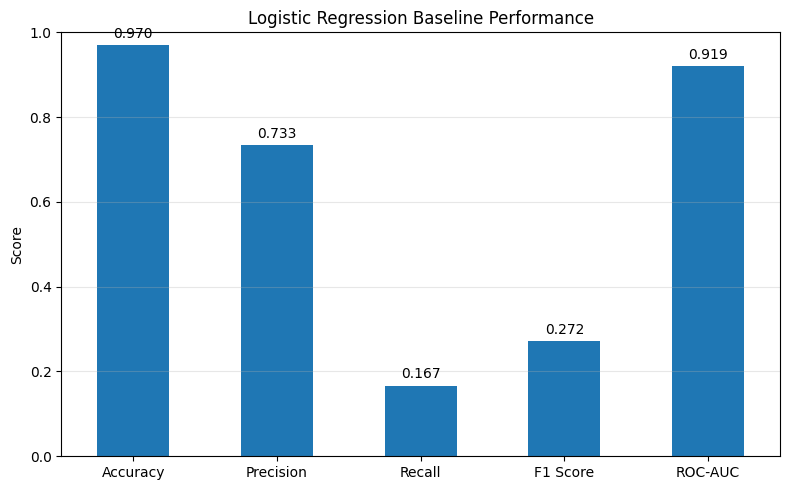

In [24]:
ax = metrics.plot(
    x="Metric",
    y="Score",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Logistic Regression Baseline Performance")
plt.xlabel("")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

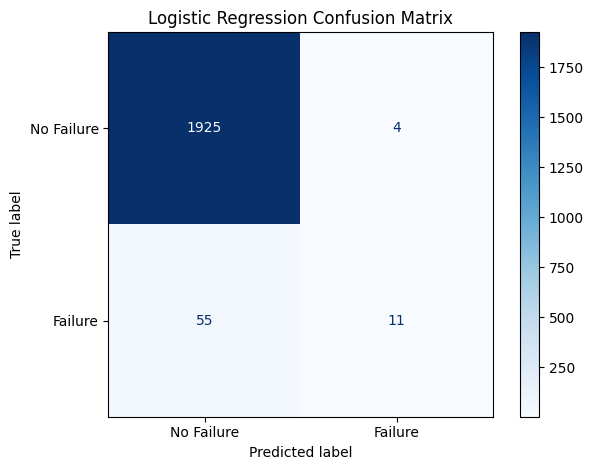

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Failure", "Failure"],
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.show()

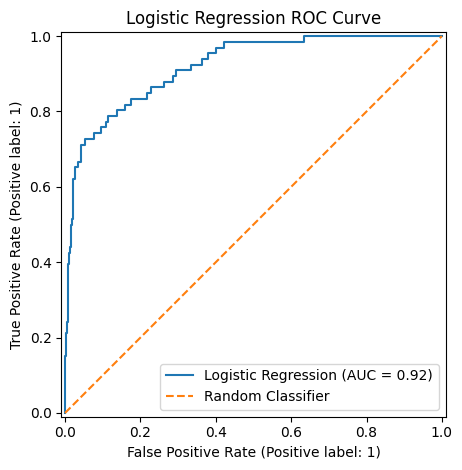

In [26]:
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression"
)

plt.title("Logistic Regression ROC Curve")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.legend()
plt.tight_layout()
plt.show()

This logistic regression creates a simple benchmark for later models to be compared against. These comparisons should use the same test set and metrics. 